# Statistics and regression
Monday October 26, 2026 • Core demo 0–45 minutes
Run all cells from top to bottom. Saved outputs are from actual offline execution.

## S1 • 0–5 min • Load a tiny dataset

Synthetic teaching data, not evidence about real students. One row represents one student. Expected: 20 rows, 0 missing values. First score is 39.5. Hours range from 1 to 20 and scores stay below 100.

In [2]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
hours = np.arange(1, 21, dtype=float)
noise = np.array([2,-2,1,-1,3,-3,2,-2,1,-1,2,-2,3,-3,1,-1,2,-2,1,-1])
df = pd.DataFrame({'study_hours': hours, 'quiz_score': 35 + 2.5*hours + noise})
df.to_csv('../data/study_hours.csv', index=False)
print(df.head().to_string(index=False))
print('Rows:', len(df), 'Missing:', int(df.isna().sum().sum()))

ModuleNotFoundError: No module named 'numpy'

## S2 • 5–10 min • Describe and compare

Expected mean and median hours: 10.5. Sample SD: 5.916. Outlier example: mean 22, median 3. SD measures spread in the original units. Pandas sample SD uses n−1; NumPy defaults to n unless ddof=1.

In [2]:
print(df.describe().round(2).to_string())
print('Mean hours:', df.study_hours.mean())
print('Median hours:', df.study_hours.median())
print('Sample SD:', round(df.study_hours.std(ddof=1), 3))
print('Mean with outlier:', np.mean([1,2,3,4,100]))
print('Median with outlier:', np.median([1,2,3,4,100]))

       study_hours  quiz_score
count        20.00       20.00
mean         10.50       61.25
std           5.92       14.77
min           1.00       38.00
25%           5.75       49.62
50%          10.50       61.00
75%          15.25       73.62
max          20.00       84.00
Mean hours: 10.5
Median hours: 10.5
Sample SD: 5.916
Mean with outlier: 22.0
Median with outlier: 3.0


## S3 • 10–17 min • Distributions and probability

Expected probability: 0.6827, about 68%. The histogram is an approximation to a bell curve. Density height is not probability: area over an interval is probability. This unbounded normal model is illustrative, not an exact model for bounded quiz scores.

P(60 <= score <= 80): 0.6827


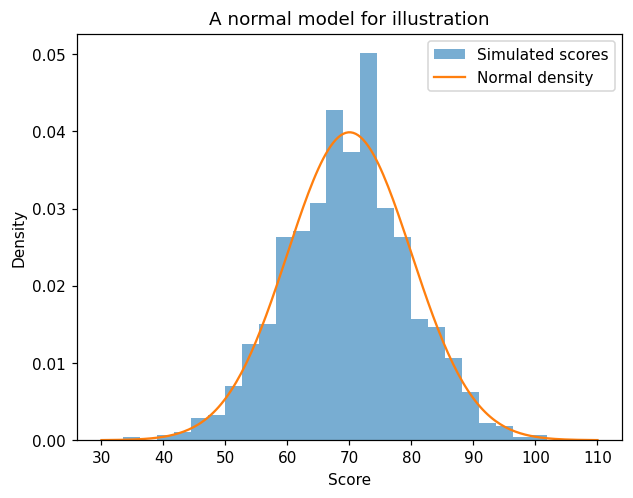

In [3]:
rng = np.random.default_rng(42)
samples = rng.normal(loc=70, scale=10, size=1000)
print('P(60 <= score <= 80):', round(stats.norm.cdf(80,70,10)-stats.norm.cdf(60,70,10), 4))
plt.hist(samples, bins=25, density=True, alpha=.6, label='Simulated scores')
x = np.linspace(30,110,200)
plt.plot(x, stats.norm.pdf(x,70,10), label='Normal density')
plt.xlabel('Score'); plt.ylabel('Density'); plt.legend(); plt.title('A normal model for illustration')

## S4 • 17–25 min • Correlation

Expected r near +0.99 and a very small p-value. r measures linear association from −1 to +1. This synthetic construction creates association. It does not establish causation. Optional: p tests zero population linear correlation under assumptions, not the probability the null is true.

Pearson r: 0.991
p-value: 4.16e-17


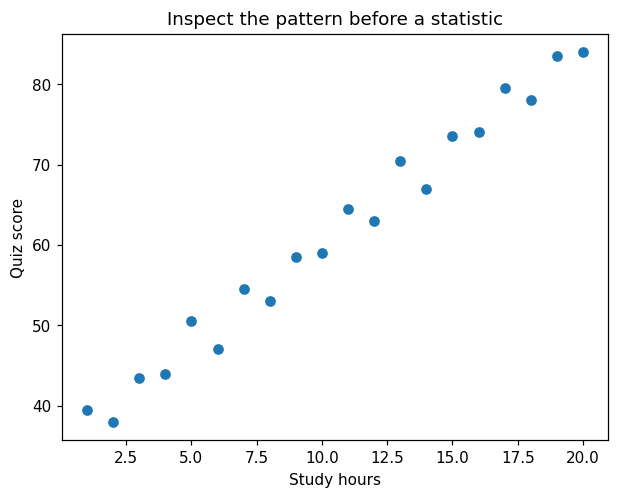

In [4]:
r, p = stats.pearsonr(df.study_hours, df.quiz_score)
print(f'Pearson r: {r:.3f}')
print(f'p-value: {p:.2e}')
plt.scatter(df.study_hours, df.quiz_score)
plt.xlabel('Study hours'); plt.ylabel('Quiz score'); plt.title('Inspect the pattern before a statistic')
assert r > .98

## S5 • 25–32 min • Split and train

Expected: 15 train rows and 5 test rows, slope around 2.5 points/hour, intercept around 35 points, prediction around 60. Training chooses intercept and slope that minimize squared training residuals. Hold out test rows before fitting.

In [5]:
X = df[['study_hours']]  # two-dimensional table, including for one feature
y = df['quiz_score']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=.25,random_state=42)
model = LinearRegression().fit(X_train, y_train)
print('Train rows:', len(X_train), 'Test rows:', len(X_test))
print(f'Intercept: {model.intercept_:.3f}, slope: {model.coef_[0]:.3f}')
print('Prediction at 10 hours:', round(model.predict(pd.DataFrame({'study_hours':[10.0]}))[0],2))

Train rows: 15 Test rows: 5
Intercept: 34.997, slope: 2.512
Prediction at 10 hours: 60.12


## S6 • 32–40 min • Evaluate on unseen rows

Expected: model MAE lower than baseline MAE, positive R² close to 1. Exact measured values are saved below. Residual = actual − prediction. MAE is average absolute miss, RMSE penalizes large misses more. R² is relative to the test-set mean predictor and can be negative; the baseline here uses the training mean.

 hours  actual  predicted  residual
   1.0    39.5      37.51      1.99
  18.0    78.0      80.22     -2.22
  16.0    74.0      75.20     -1.20
   2.0    38.0      40.02     -2.02
   9.0    58.5      57.61      0.89
MAE: 1.664 points
RMSE: 1.744 points
R2: 0.989
Baseline MAE: 15.693


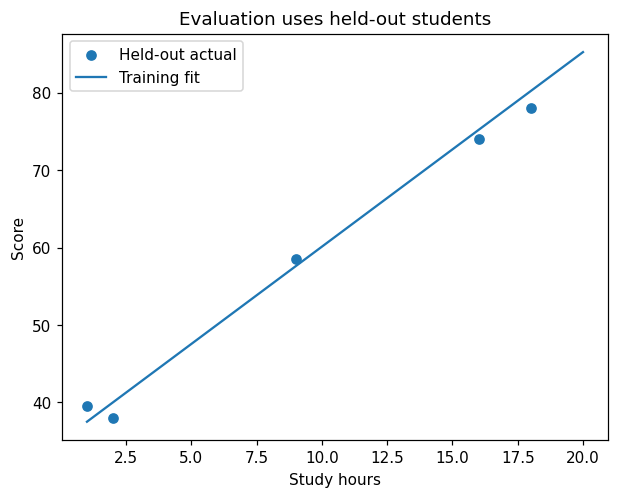

In [6]:
pred = model.predict(X_test)
baseline = DummyRegressor(strategy='mean').fit(X_train,y_train)
base_pred = baseline.predict(X_test)
print(pd.DataFrame({'hours':X_test.study_hours,'actual':y_test,'predicted':pred,'residual':y_test-pred}).round(2).to_string(index=False))
print(f'MAE: {mean_absolute_error(y_test,pred):.3f} points')
print(f'RMSE: {np.sqrt(mean_squared_error(y_test,pred)):.3f} points')
print(f'R2: {r2_score(y_test,pred):.3f}')
print(f'Baseline MAE: {mean_absolute_error(y_test,base_pred):.3f}')
assert mean_absolute_error(y_test,pred) < mean_absolute_error(y_test,base_pred)
plt.scatter(X_test.study_hours,y_test,label='Held-out actual')
grid = pd.DataFrame({'study_hours':np.linspace(1,20,100)})
plt.plot(grid.study_hours,model.predict(grid),label='Training fit')
plt.xlabel('Study hours'); plt.ylabel('Score'); plt.legend(); plt.title('Evaluation uses held-out students')

## S7 • 40–45 min • A two-minute modification

Expected: predictions roughly 47.5, 65, and 110. A score above 100 exposes the model limitation. Do not silently clip it and claim the model improved. Discuss more data or a better model. Optional homework: repeat with another split, then consider a nonlinear pattern.

In [7]:
new_hours = pd.DataFrame({'study_hours':[5.,12.,30.]})
print(new_hours.assign(prediction=model.predict(new_hours)).round(2).to_string(index=False))
print('30 hours is outside the observed 1–20 hour range: extrapolation.')

 study_hours  prediction
         5.0       47.56
        12.0       65.15
        30.0      110.37
30 hours is outside the observed 1–20 hour range: extrapolation.
